In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from hallucination_features import FEATURE_COLS, build_augmented_lr_pipeline, light_clean
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold
from pathlib import Path

In [2]:
DATA_DIR = Path.cwd() / "data"
if not (DATA_DIR / "llm_hallucination_dataset_v1.csv").is_file():
    DATA_DIR = Path.cwd().parent / "data"
DATASET_CSV = DATA_DIR / "llm_hallucination_dataset_v1.csv"

llm_df = pd.read_csv(DATASET_CSV)
llm_df = llm_df.drop(columns=["notes"])

In [3]:
llm_df["prompt_text"] = llm_df["prompt_text"].astype(str)
llm_df["response_text"] = llm_df["response_text"].astype(str)
llm_df["response_clean"] = llm_df["response_text"].map(light_clean)

y = llm_df["hallucination_label"]
groups = llm_df["prompt_text"]
X = llm_df[FEATURE_COLS]

In [4]:
pipeline = build_augmented_lr_pipeline()

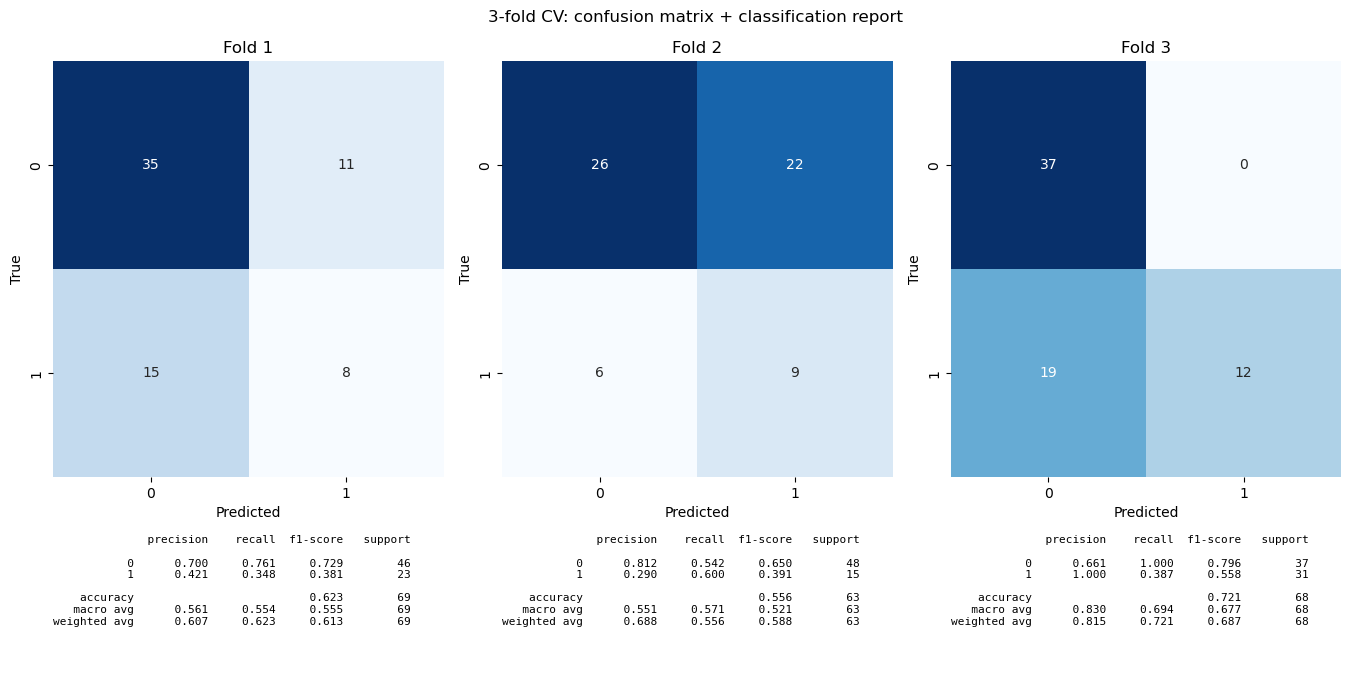

In [5]:
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=1)

fig, axes = plt.subplots(2, 3, figsize=(14, 7), gridspec_kw={"height_ratios": [1.0, 0.35]})

fold_accuracy = []
fold_precision = []
fold_recall = []
fold_f1 = []

for fold_idx, (tr_idx, val_idx) in enumerate(cv.split(X, y, groups)):
    X_tr = X.iloc[tr_idx]
    y_tr = y.iloc[tr_idx]
    X_val = X.iloc[val_idx]
    y_val = y.iloc[val_idx]

    fold_pipeline = clone(pipeline)
    fold_pipeline.fit(X_tr, y_tr)
    y_val_pred = fold_pipeline.predict(X_val)

    cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=[0, 1],
        yticklabels=[0, 1],
        ax=axes[0, fold_idx],
    )
    axes[0, fold_idx].set_xlabel("Predicted")
    axes[0, fold_idx].set_ylabel("True")
    axes[0, fold_idx].set_title(f"Fold {fold_idx + 1}")

    report = classification_report(
        y_val, y_val_pred, digits=3, zero_division=0
    )
    axes[1, fold_idx].axis("off")
    axes[1, fold_idx].text(
        0.0,
        1.0,
        report,
        transform=axes[1, fold_idx].transAxes,
        fontsize=8,
        verticalalignment="top",
        horizontalalignment="left",
        family="monospace",
    )

    fold_accuracy.append((y_val_pred == y_val).mean())
    fold_precision.append(precision_score(y_val, y_val_pred, zero_division=0))
    fold_recall.append(recall_score(y_val, y_val_pred, zero_division=0))
    fold_f1.append(f1_score(y_val, y_val_pred, zero_division=0))

fig.suptitle("3-fold CV: confusion matrix + classification report")
plt.tight_layout()
plt.show()

In [6]:
print(f"3-fold average test_accuracy: {np.mean(fold_accuracy):.3f}")
print(f"3-fold average test_precision: {np.mean(fold_precision):.3f}")
print(f"3-fold average test_recall: {np.mean(fold_recall):.3f}")
print(f"3-fold average test_f1: {np.mean(fold_f1):.3f}")

3-fold average test_accuracy: 0.633
3-fold average test_precision: 0.570
3-fold average test_recall: 0.445
3-fold average test_f1: 0.443
